# C-06: Codon use in the reporter reference

**Task:** Compare the supplied coding sequence with a historical yeast codon reference.

**Inputs:** GenBank reporter reference and the EMBOSS 24-CDS yeast count table.

**Motivation:** Locate sequence features relevant to a future synonymous-redesign comparison.

**Goal:** Calculate coding integrity, CAI, local weights and base composition.

**Prediction:** Codon choices and local weights will vary along the sequence.

In [1]:
# Imports and editable settings. Start Jupyter anywhere within this project.
from pathlib import Path
from collections import Counter
from itertools import groupby
from datetime import datetime, timezone
import hashlib
import io
import json
import math
import platform
import re
import warnings
import Bio
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from Bio import SeqIO
from Bio.Data import CodonTable
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/input").is_dir() and (p / "tasks").is_dir())
DNA_FILE = ROOT / "data/input/construct_reference.gbk"
COUNT_FILE = ROOT / "data/input/yeast_codon_reference.cut"
OUT = ROOT / "data/output/C-06"
FEATURE_LABEL = "CGaMP6F"
FIRST_N = 50
ZERO_COUNT = 0.5  # Replace only genuinely absent reference counts.
LOW_WEIGHT = 0.2  # Descriptive cutoff, not an expression threshold.
MIN_CLUSTER = 2
MIN_AT_RUN = 6
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "savefig.dpi": 300, "svg.fonttype": "none"})
input_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                for p in [DNA_FILE, COUNT_FILE]}

## Materials and methods: coding sequence

Select the CDS labelled `CGaMP6F`. Format only the nonstandard LOCUS metadata spacing in memory and preserve raw bytes, features and ORIGIN bases. Translate with standard nuclear code 1 and compare the annotated protein. Record the adjacent stop separately. Coordinates are one-based and inclusive.

**Scope and working assumptions.** The supplied GenBank reference is the analysis sequence. Codon weights use integer counts from the historical 24-CDS yeast table, with the stated zero-count convention. This sequence-level comparison covers coding integrity and codon composition; tested-clone identity, strain-specific expression, transcript context and cadmium performance are outside its scope.

In [2]:
# Format only the nonstandard LOCUS line; leave original bytes untouched.
raw_text = DNA_FILE.read_text(encoding="utf-8")
header, body = raw_text.split("\n", 1)
parts = header.split()
stub = SeqRecord(Seq(None, length=int(parts[2])), id=parts[1], name=parts[1], description="")
stub.annotations.update(molecule_type="DNA", topology="linear", date=parts[-1], data_file_division="UNK")
buffer = io.StringIO()
SeqIO.write(stub, buffer, "genbank")
normalized_header = buffer.getvalue().splitlines()[0]
with warnings.catch_warnings(record=True) as parser_warnings:
    warnings.simplefilter("always")
    record = SeqIO.read(io.StringIO(normalized_header + "\n" + body), "genbank")
origin = "".join(re.findall("[A-Za-z]+", raw_text.split("\nORIGIN", 1)[1].split("//", 1)[0])).upper()
assert str(record.seq) == origin and len(record) == int(parts[2])
features = [f for f in record.features if f.type == "CDS"
            and FEATURE_LABEL in f.qualifiers.get("label", [])]
assert len(features) == 1, "The labelled reporter CDS must be unique."
feature = features[0]
assert feature.location.strand == 1, "This notebook expects the supplied forward CDS."
assert int(feature.qualifiers.get("transl_table", [1])[0]) == 1
assert int(feature.qualifiers.get("codon_start", [1])[0]) == 1
dna = str(feature.extract(record.seq)).upper()
assert set(dna) <= set("ACGT") and len(dna) % 3 == 0
protein = str(feature.extract(record.seq).translate(table=1))
assert "*" not in protein, "Unexpected stop inside the labelled CDS."
annotation_match = protein == feature.qualifiers.get("translation", [""])[0]
start, end = int(feature.location.start) + 1, int(feature.location.end)
adjacent = str(record.seq[end:end + 3]).upper()
genetic_code = CodonTable.unambiguous_dna_by_id[1]
has_stop = adjacent in genetic_code.stop_codons
codons = [dna[i:i + 3] for i in range(0, len(dna), 3)]
assert dna[:3] == "ATG" and annotation_match
(OUT / "reference_CDS.fna").write_text(f">{FEATURE_LABEL}_annotated_CDS\n{dna}\n")
(OUT / "reference_protein.faa").write_text(f">{FEATURE_LABEL}_reference\n{protein}\n");

## Materials and methods: codon adaptation

Use the integer Number column. Within each complete synonymous family, weight = count / maximum count; group all six Leu, Arg and Ser codons by amino acid. Replace true zeros by 0.5; exclude Met, Trp and stops from the geometric-mean CAI. Repeat with zero replacement 1. Compare the whole CDS and first 50 codons, including annotated tags. References: Sharp & Li (1987), doi:10.1093/nar/15.3.1281; Xia (2007), doi:10.1177/117693430700300028.

In [3]:
rows = []
for line in COUNT_FILE.read_text(encoding="utf-8").splitlines():
    fields = line.split()
    if len(fields) == 5 and re.fullmatch("[ACGT]{3}", fields[0]):
        rows.append([fields[0], fields[1], float(fields[2]), int(fields[4])])
reference = pd.DataFrame(rows, columns=["codon", "aa", "rounded_fraction", "count"])
assert len(reference) == 64 and reference.codon.nunique() == 64
assert all(genetic_code.forward_table.get(r.codon, "*") == r.aa
           for r in reference.itertuples())
def make_weights(zero):
    adjusted = reference["count"].replace(0, zero)
    return dict(zip(reference.codon, adjusted / adjusted.groupby(reference.aa).transform("max")))
weights, sensitivity = make_weights(ZERO_COUNT), make_weights(1)
def cai(sequence_codons, weight_map):
    terms = [math.log(weight_map[c]) for c in sequence_codons
             if genetic_code.forward_table[c] not in {"M", "W"}]
    return math.exp(sum(terms) / len(terms)) if terms else None
full_cai, first_cai = cai(codons, weights), cai(codons[:FIRST_N], weights)
alternative_cai = cai(codons, sensitivity)
per_codon = pd.DataFrame({"position_aa": range(1, len(codons) + 1), "codon": codons})
per_codon["aa"] = list(protein)
per_codon["reference_weight"] = per_codon.codon.map(weights)
per_codon["low_weight"] = per_codon.reference_weight < LOW_WEIGHT
per_codon["cds_nt_start"] = per_codon.position_aa * 3 - 2
per_codon["reference_nt_start"] = start + per_codon.cds_nt_start - 1
per_codon.to_csv(OUT / "per_codon.csv", index=False)
reference["weight_zero_0_5"] = reference.codon.map(weights)
reference["weight_zero_1"] = reference.codon.map(sensitivity)
reference.to_csv(OUT / "reference_weights.csv", index=False)
usage = Counter(codons)
reference.assign(target_count=reference.codon.map(usage).fillna(0).astype(int)).to_csv(
    OUT / "codon_usage.csv", index=False)

## Materials and methods: sequence features

Locate stretches of at least two codons with weight below 0.2. Calculate overall GC and GC at each codon position. Record A/T homopolymers and N-terminal His stretches of at least six residues. These are descriptive sequence features.

In [4]:
flags, clusters = [], []
for low, group in groupby(per_codon.itertuples(), key=lambda r: r.low_weight):
    positions = [r.position_aa for r in group]
    if low and len(positions) >= MIN_CLUSTER:
        clusters.append((positions[0], positions[-1]))
        flags.append(["low_weight_cluster", positions[0] * 3 - 2, positions[-1] * 3,
                      f"codons {positions[0]}-{positions[-1]}; weight < {LOW_WEIGHT}"])
for match in re.finditer(r"A{%d,}|T{%d,}" % (MIN_AT_RUN, MIN_AT_RUN), dna):
    flags.append(["AT_homopolymer", match.start() + 1, match.end(), match.group()])
his = re.search(r"H{6,}", protein[:40])
if his:
    flags.append(["N_terminal_His_tag", his.start() * 3 + 1, his.end() * 3,
                  f"His{len(his.group())} at residues {his.start() + 1}-{his.end()}"])
flag_table = pd.DataFrame(flags, columns=["feature", "cds_nt_start", "cds_nt_end", "detail"])
flag_table.to_csv(OUT / "sequence_flags.csv", index=False)
def gc(sequence):
    return 100 * sum(b in "GC" for b in sequence) / len(sequence)
gc_values = [gc(dna), gc(dna[0::3]), gc(dna[1::3]), gc(dna[2::3])]
longest_at = {base: max((len(m.group()) for m in re.finditer(base + "+", dna)), default=0)
              for base in "AT"}
assert all(hashlib.sha256(p.read_bytes()).hexdigest() == input_hashes[p.name]
           for p in [DNA_FILE, COUNT_FILE]), "An input changed during the calculation."
provenance = {"input_sha256": input_hashes, "utc": datetime.now(timezone.utc).isoformat(),
              "parsing": {"original_LOCUS": header, "in_memory_LOCUS": normalized_header,
                          "origin_bases_unchanged": True, "warnings": [str(w.message) for w in parser_warnings]},
              "runtime": {"Python": platform.python_version(), "Biopython": Bio.__version__,
                          "numpy": np.__version__, "pandas": pd.__version__,
                          "matplotlib": matplotlib.__version__},
              "settings": {"genetic_code": 1, "zero_count": ZERO_COUNT, "low_weight": LOW_WEIGHT,
                           "first_codons": FIRST_N, "min_cluster": MIN_CLUSTER, "min_AT_run": MIN_AT_RUN},
              "reference_scope": "24 CDS, S. cerevisiae, TranstermMay1994; integer Number field"}
(OUT / "source_hashes_runtime.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8");

## Results

The following cells calculate all reported values from G1 and R1. Figure 1 shows local weights and CAI on their full 0–1 scales; Figure 2 shows GC composition. These are deterministic results from one supplied reference sequence, so no biological error bars are used. CSV files retain every codon, reference weight and flagged location.

,Metric,Value,Input data,Finished without more wet-lab data?
0,Labelled CDS,1350 nt; 450 aa,G1,Yes: reference scope
1,Reference coordinates,748-2097,G1,Yes: reference scope
2,Adjacent stop,TAA; 2098-2100,G1,Yes: reference scope
3,"CAI, whole CDS",0.1708,G1 + R1,Yes: reference scope
4,"CAI, first 50 codons",0.1495,G1 + R1,Yes: reference scope
5,"CAI, zero-count replacement 1",0.1764,G1 + R1,Yes: reference scope
6,GC / GC3,40.37% / 35.78%,G1,Yes: reference scope
7,Codons with weight < 0.2,185/450,G1 + R1,Yes: reference scope
8,Consecutive low-weight stretches,40,G1 + R1,Yes: reference scope
9,Longest A / T homopolymer,5 / 8 nt,G1,Yes: reference scope


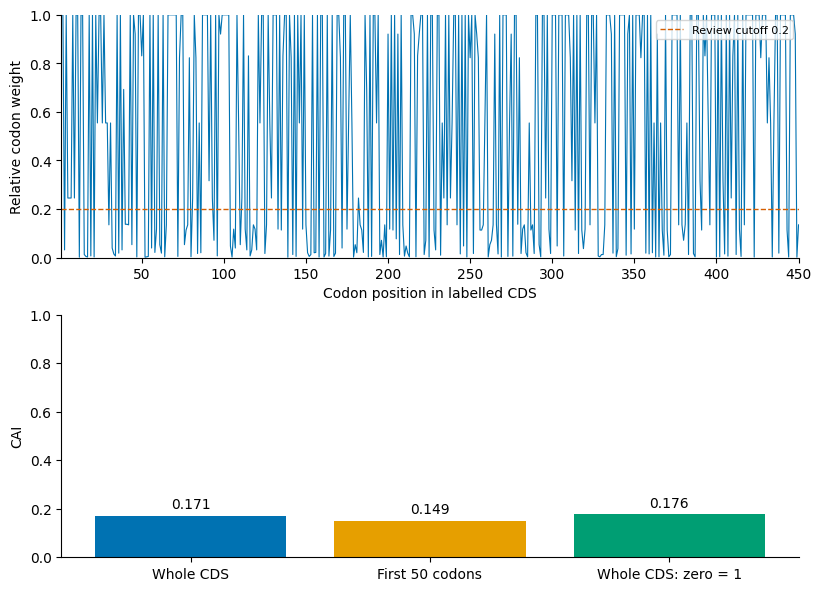

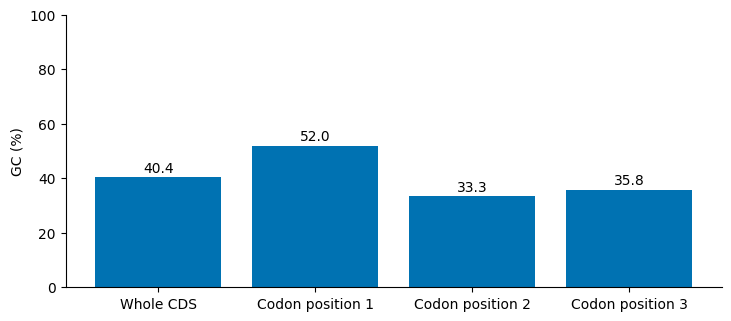

In [5]:
low_n = int(per_codon.low_weight.sum())
metrics = [("Labelled CDS", f"{len(dna)} nt; {len(protein)} aa", "G1"),
           ("Reference coordinates", f"{start}-{end}", "G1"),
           ("Adjacent stop", f"{adjacent}; {end + 1}-{end + 3}", "G1"),
           ("CAI, whole CDS", f"{full_cai:.4f}", "G1 + R1"),
           (f"CAI, first {FIRST_N} codons", f"{first_cai:.4f}", "G1 + R1"),
           ("CAI, zero-count replacement 1", f"{alternative_cai:.4f}", "G1 + R1"),
           ("GC / GC3", f"{gc_values[0]:.2f}% / {gc_values[3]:.2f}%", "G1"),
           (f"Codons with weight < {LOW_WEIGHT}", f"{low_n}/{len(codons)}", "G1 + R1"),
           ("Consecutive low-weight stretches", str(len(clusters)), "G1 + R1"),
           ("Longest A / T homopolymer", f"{longest_at['A']} / {longest_at['T']} nt", "G1"),
           ("N-terminal His stretch", his.group() if his else "None in first 40 aa", "G1")]
table = pd.DataFrame(metrics, columns=["Metric", "Value", "Input data"])
table["Finished without more wet-lab data?"] = "Yes: reference scope"
display(table)
table.to_csv(OUT / "results_table.csv", index=False)
fig, axes = plt.subplots(2, 1, figsize=(8.1, 5.8), layout="constrained")
axes[0].plot(per_codon.position_aa, per_codon.reference_weight, color="#0072B2", lw=0.8)
axes[0].axhline(LOW_WEIGHT, color="#D55E00", ls="--", lw=1, label="Review cutoff 0.2")
axes[0].set(xlabel="Codon position in labelled CDS", ylabel="Relative codon weight", ylim=(0, 1), xlim=(1, len(codons)))
axes[0].legend(loc="upper right", fontsize=8)
axes[1].bar(["Whole CDS", f"First {FIRST_N} codons", "Whole CDS: zero = 1"],
            [full_cai, first_cai, alternative_cai], color=["#0072B2", "#E69F00", "#009E73"])
axes[1].set(ylabel="CAI", ylim=(0, 1))
for x, value in enumerate([full_cai, first_cai, alternative_cai]):
    axes[1].text(x, value + 0.03, f"{value:.3f}", ha="center")
fig.savefig(OUT / "codon_adaptation.png", bbox_inches="tight")
fig.savefig(OUT / "codon_adaptation.svg", bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(figsize=(7.2, 3.1), layout="constrained")
ax.bar(["Whole CDS", "Codon position 1", "Codon position 2", "Codon position 3"], gc_values, color="#0072B2")
ax.set(ylabel="GC (%)", ylim=(0, 100))
for x, value in enumerate(gc_values):
    ax.text(x, value + 2, f"{value:.1f}", ha="center")
fig.savefig(OUT / "gc_composition.png", bbox_inches="tight")
fig.savefig(OUT / "gc_composition.svg", bbox_inches="tight")
plt.show()

In [6]:
# Interpretation stays tied to the sequence and reference actually analysed.
results = [f"The labelled CDS spans reference bases {start}-{end}: {len(dna)} nt and {len(protein)} aa; its translation matches its annotation.",
           f"The adjacent triplet is {adjacent}; a start-to-adjacent-stop segment has {len(dna) + 3 if has_stop else 'unresolved'} nt.",
           f"Count-derived yeast-reference CAI is {full_cai:.4f}, versus {first_cai:.4f} in the first {FIRST_N} codons; zero = 1 gives {alternative_cai:.4f}.",
           f"There are {low_n}/{len(codons)} low-weight codons and {len(clusters)} consecutive stretches of at least {MIN_CLUSTER} codons; GC is {gc_values[0]:.2f}% and GC3 is {gc_values[3]:.2f}%."]
conclusion = ((f"The {len(dna)}-nt reporter CDS encodes {len(protein)} amino acids and matches its annotated translation. "
              f"Its yeast-reference CAI is {full_cai:.4f}, compared with {first_cai:.4f} in the first {FIRST_N} codons. "
              f"There are {low_n} low-weight codon positions and {len(clusters)} consecutive stretches of at least {MIN_CLUSTER} codons, locating regions for a synonymous-redesign comparison."))
limitations = []
summary = {"title": "C-06: codon use in the supplied reporter reference", "question": "How does the reference CDS compare with historical highly expressed yeast codon counts?",
           "materials": ["G1: construct_reference.gbk; original project GenBank reference.", "R1: yeast_codon_reference.cut; EMBOSS Eyeast_cai, 24 CDS, TranstermMay1994."],
           "methods": ["Format only LOCUS metadata spacing in memory; verify ORIGIN bases and raw-file hashes are unchanged. Extract the labelled CDS and translate with standard nuclear code 1; record adjacent stop separately.",
                       "Derive weights from integer counts within full synonymous families; replace true zeros by 0.5; exclude Met, Trp and stops from CAI. Sensitivity: zero = 1.",
                       "Compare whole CDS and first 50 codons; measure GC by position and flag low-weight clusters and A/T homopolymers."],
           "results": results, "conclusion": conclusion, "limitations": [],
           "figures": [{"file": "codon_adaptation.png", "caption": "G1 CDS weights and CAI using R1 integer counts. CAI excludes Met/Trp; zero counts replaced by 0.5, with zero = 1 sensitivity. Cutoff 0.2 is descriptive. One reference sequence; no biological error bars."},
                       {"file": "gc_composition.png", "caption": "GC percentage in G1 overall and by codon position. One deterministic reference sequence; no biological error bars."}],
           "references": ["Sharp & Li (1987), doi:10.1093/nar/15.3.1281.", "Xia (2007), doi:10.1177/117693430700300028.", "EMBOSS CAI manual: https://emboss.sourceforge.net/apps/cvs/emboss/apps/cai.html", "Count source: https://sources.debian.org/data/main/e/emboss/6.6.0%2Bdfsg-15/emboss/data/CODONS/Eyeast_cai.cut"],
           "table": {"columns": table.columns.tolist(), "rows": table.values.tolist()}}
summary["scope_and_assumptions"] = 'The supplied GenBank reference is the analysis sequence. Codon weights use integer counts from the historical 24-CDS yeast table, with the stated zero-count convention. This sequence-level comparison covers coding integrity and codon composition; tested-clone identity, strain-specific expression, transcript context and cadmium performance are outside its scope.'
summary.pop("limitations", None)
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
display(Markdown("## Conclusion and interpretation\n\n" + conclusion))

## Conclusion and interpretation

The 1350-nt reporter CDS encodes 450 amino acids and matches its annotated translation. Its yeast-reference CAI is 0.1708, compared with 0.1495 in the first 50 codons. There are 185 low-weight codon positions and 40 consecutive stretches of at least 2 codons, locating regions for a synonymous-redesign comparison.